# Scheme x decoder: logical error rate vs distance at $p_z = 10^{-2}$, $p_\mathrm{res} = 10^{-4}$

Data: all files matching `out/collection/ler_vs_d_pz1e-2_pres1e-4*.csv` (batches are summed per configuration; produced by `tools/run_ler_vs_d_pz1e3_pres1e4.sh` with `P_Z=1e-2`).

Curves are keyed by **(scheme, decoder)**: scheme sets the line style / marker, decoder sets the color. To add a decoder or scheme later, extend `DECODER_COLORS` / `SCHEME_STYLES` below.

In [1]:
import ast
import json
from glob import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import beta

CSV_GLOB = "../out/collection/ler_vs_d_pz1e-2_pres1e-4*.csv"

paths = sorted(glob(CSV_GLOB))
assert paths, f"no CSVs matched {CSV_GLOB}"
print("loading:")
for path in paths:
    print(f"  {path}")
raw = pd.concat(
    [pd.read_csv(path, skipinitialspace=True) for path in paths],
    ignore_index=True,
)
raw.columns = [c.strip() for c in raw.columns]

# The CSVs may hold multiple measurement batches per configuration (same
# strong_id), both within and across files. Combine them by summing
# shots/errors/discards/seconds, keeping the shared decoder + metadata.
df = (
    raw.groupby("strong_id", sort=False)
    .agg(
        decoder=("decoder", "first"),
        json_metadata=("json_metadata", "first"),
        shots=("shots", "sum"),
        errors=("errors", "sum"),
        discards=("discards", "sum"),
        seconds=("seconds", "sum"),
    )
    .reset_index()
)
print(f"combined {len(raw)} rows from {len(paths)} file(s) -> {len(df)} configurations")


def parse_metadata(s):
    # sinter-format CSVs (--resume) store JSON; dated append CSVs store a
    # Python dict repr (single quotes), so fall back to literal_eval.
    try:
        return json.loads(s)
    except (json.JSONDecodeError, TypeError):
        return ast.literal_eval(s)


meta = df["json_metadata"].apply(parse_metadata)
df["d"] = meta.apply(lambda m: m["expected_distance"])
df["rounds"] = meta.apply(lambda m: m["rounds"])
df["p"] = meta.apply(lambda m: m["p"])
df["p_bell_z"] = meta.apply(lambda m: m["p_bell_z"])
df["noise_model"] = meta.apply(lambda m: m["noise_model"])
df["ler"] = df["errors"] / df["shots"]

assert (df["p"] == 1e-4).all(), "expected all p (= p_res) == 1e-4"
assert (df["p_bell_z"] == 1e-2).all(), "expected all p_bell_z == 1e-2"
df[["noise_model", "decoder", "d", "rounds", "shots", "errors", "ler"]].sort_values(
    ["noise_model", "decoder", "d"]
)

loading:
  ../out/collection/ler_vs_d_pz1e-2_pres1e-4,2026-09-01.csv
combined 12 rows from 1 file(s) -> 12 configurations


,noise_model,decoder,d,rounds,shots,errors,ler
0,biased_bell_v3_equivalent,pymatching,3,10,40755,2350,0.057662
1,biased_bell_v3_equivalent,pymatching,5,16,80759,2576,0.031897
2,biased_bell_v3_equivalent,pymatching,7,22,110318,2342,0.021230
6,biased_bell_v3_equivalent,pymatching-correlated,3,10,80213,2423,0.030207
7,biased_bell_v3_equivalent,pymatching-correlated,5,16,220023,2368,0.010763
8,biased_bell_v3_equivalent,pymatching-correlated,7,22,577470,2159,0.003739
3,biased_bell_v3_equivalent_majority,pymatching,3,10,4355716,2322,0.000533
4,biased_bell_v3_equivalent_majority,pymatching,5,16,5000000,16,0.000003
5,biased_bell_v3_equivalent_majority,pymatching,7,22,5000000,0,0.000000
9,biased_bell_v3_equivalent_majority,pymatching-correlated,3,10,5000000,1321,0.000264


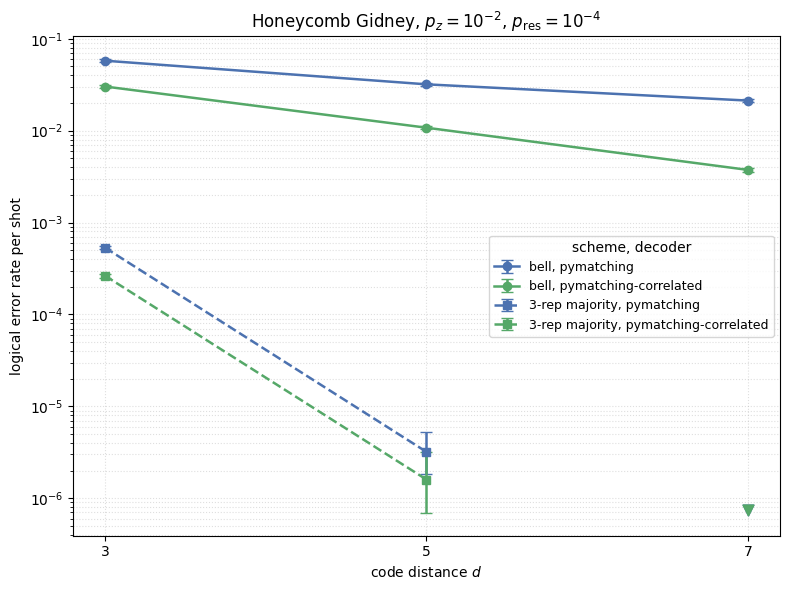

In [2]:
def clopper_pearson(errors, shots, alpha=0.05):
    """Two-sided Clopper-Pearson (exact binomial) confidence interval."""
    errors = np.asarray(errors, dtype=float)
    shots = np.asarray(shots, dtype=float)
    lo = beta.ppf(alpha / 2, errors, shots - errors + 1)
    hi = beta.ppf(1 - alpha / 2, errors + 1, shots - errors)
    lo = np.where(errors == 0, 0.0, lo)
    hi = np.where(errors == shots, 1.0, hi)
    return lo, hi


# Color = decoder, line style / marker = scheme. Extend these dicts to add
# more decoders or schemes; unknown keys fall back to matplotlib defaults.
DECODER_COLORS = {
    "pymatching": "#4C72B0",
    "pymatching-correlated": "#55A868",
    "belief_matching": "#C44E52",
    "tesseract_short": "#DD8452",
}
SCHEME_STYLES = {
    "biased_bell_v3_equivalent": dict(label="bell", linestyle="-", marker="o"),
    "biased_bell_v3_equivalent_majority": dict(label="3-rep majority", linestyle="--", marker="s"),
    "biased_bell_v3_equivalent_fullrep3": dict(label="3-rep full decode", linestyle="-.", marker="^"),
}

fig, ax = plt.subplots(figsize=(8, 6))

for (noise_model, decoder), g in df.sort_values("d").groupby(["noise_model", "decoder"]):
    style = SCHEME_STYLES.get(noise_model, dict(label=noise_model, linestyle="-", marker="o"))
    color = DECODER_COLORS.get(decoder)
    label = f"{style['label']}, {decoder}"

    d = g["d"].to_numpy()
    ler = g["ler"].to_numpy()
    lo, hi = clopper_pearson(g["errors"], g["shots"])

    # Connecting line + error bars only for points with observed errors; a
    # zero-error point has no measured rate, so joining a line to it is
    # misleading.
    real = ler > 0
    yerr = np.vstack([ler[real] - lo[real], hi[real] - ler[real]])
    eb = ax.errorbar(
        d[real], ler[real], yerr=yerr,
        marker=style["marker"], linestyle=style["linestyle"],
        capsize=4, lw=1.8, label=label, color=color,
    )
    color = eb.lines[0].get_color()  # resolved color for the triangles

    # zero-error points: no line, plotted at the 95% upper bound as an
    # upper-limit triangle.
    if (~real).any():
        ax.scatter(
            d[~real], hi[~real],
            marker="v", s=60, color=color, zorder=5,
        )

ax.set_yscale("log")
ax.set_xticks(sorted(df["d"].unique()))
ax.set_xlabel("code distance $d$")
ax.set_ylabel("logical error rate per shot")
ax.set_title(r"Honeycomb Gidney, $p_z = 10^{-2}$, $p_\mathrm{res} = 10^{-4}$")
ax.grid(True, which="both", ls=":", alpha=0.4)
ax.legend(title="scheme, decoder", fontsize=9)
fig.tight_layout()
plt.show()

Downward triangles mark points with **zero observed errors** (LER = 0 cannot be shown on a log axis); they are plotted at the 95% Clopper–Pearson upper bound and represent an upper limit only.